# 🛒 PROGRESS REPORT 2 • PROYEK AKHIR DATA SCIENCE (POIN 1 – 14)
# Segmentasi Profil & Perilaku Pelanggan Ritel Menggunakan Metode Clustering
### Berdasarkan Pendapatan Tahunan dan Riwayat Transaksi Belanja (Dataset Customer Personality Analysis)

---

**TIM PENYUSUN (INFORMATIKA UPN "VETERAN" YOGYAKARTA):**
1. **Grahito Ardianto Purnomo** (123240001)
2. **Fahri Hidayatullah** (123240002)
3. **Krocasadigandra Arzaq Kubro M.** (123240015)
4. **Gian Abi Firdaus** (123240017)

**DOSEN PENGAMPU:**
- **Dhimas Arief Dharmawan, S.T., Ph.D.**

---

### Ringkasan Eksekutif & Struktur Dokumen
Notebook ini merupakan implementasi komputasi komprehensif dari **Progress Report 2 (Poin 1 hingga 14)** yang mencakup 6 aspek utama metodologi CRISP-DM:
- **Aspek 1: Data Understanding (Poin 1 – 5)**: Sumber data, lisensi CC0, kamus data 4 dimensi, audit kualitas awal, EDA berinsight, dan evaluasi 5 risiko bias sampel.
- **Aspek 2: Exploratory Data Analysis / EDA (Poin 6 – 8)**: Statistik deskriptif, visualisasi fitur kunci vs profil, dan 4 insight korelasi untuk keputusan pemodelan.
- **Aspek 3: Audit Kualitas Data (Poin 9)**: Audit kuantitatif missing values, duplikasi profil, anomali input, dan analisis outlier metode IQR 1,5×.
- **Aspek 4: Data Cleaning (Poin 10 – 11)**: Eksekusi 5 strategi pembersihan data dan komparasi kondisi sebelum vs sesudah cleaning.
- **Aspek 5: Preprocessing (Poin 12 – 13)**: Ordinal & binary encoding, scaling log1p + StandardScaler, mitigasi data imbalance tanpa SMOTE, dan pemisahan dataset 80:20 (train-test).
- **Aspek 6: Feature Selection & Engineering (Poin 14)**: Rekayasa fitur siklus hidup & agregat belanja, serta justifikasi pemilahan fitur modeling vs fitur profiling pasca-cluster.

## 0. Setup Lingkungan & Import Library

Pada tahap inisialisasi ini, pustaka komputasi numerik, analisis data tabular, visualisasi grafis, serta prapemrosesan scikit-learn dimuat. Nilai random seed dikunci pada `RANDOM_STATE = 42` untuk menjamin reproduktibilitas seluruh proses komputasi.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

# Konfigurasi visualisasi & opsi tampilan pandas
sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

RANDOM_STATE = 42
DATA_PATH = "marketing_campaign.csv"
REF_YEAR = 2014   # Tahun referensi pencatatan dataset

print("Lingkungan eksekusi berhasil disiapkan:")
print(" - Pandas      :", pd.__version__)
print(" - NumPy       :", np.__version__)
print(" - Random Seed :", RANDOM_STATE)

Lingkungan eksekusi berhasil disiapkan:
 - Pandas      : 3.0.3
 - NumPy       : 2.4.6
 - Random Seed : 42


---
# ASPEK 1: DATA UNDERSTANDING

## Poin 1: Sumber Data, Lisensi & Kesiapan Data

### 1.1 Sumber & Konteks Akuisisi
- **Repositori Asal**: Kaggle (*Customer Personality Analysis*).
- **Penyedia Data**: Dr. Omar Romero-Hernandez (diunggah oleh akun `imakash3011`).
- **Dimensi Mentah**: 2.240 baris (pelanggan ritel) dan 29 kolom atribut.
- **Format Berkas**: CSV dengan delimiter karakter Tab (`\t`).
- **Rentang Registrasi**: 30 Juli 2012 hingga 29 Juni 2014.

### 1.2 Izin, Privasi & Tingkat Kesiapan Data (*Data Readiness*)
- **Hak Pakai**: Dataset berlisensi **Creative Commons Public Domain (CC0 1.0)**, sehingga bebas disalin, dimodifikasi, dan dipakai untuk riset akademik maupun komersial tanpa kewajiban royalti.
- **Kepatuhan Privasi (UU PDP & GDPR)**: Data telah teranonimkan murni tanpa atribut pengenal langsung seperti nama, nomor kontak, email, maupun alamat tempat tinggal. Satu-satunya pengenal adalah angka unik `ID`.
- **Status Data Readiness (Lawrence, 2017)**: Berada pada level **Band C menuju Band B**. Data siap dibaca secara programmatic (Band C), namun memerlukan penanganan nilai kosong, perbaikan anomali tahun lahir/income, dan standardisasi skala sebelum pemodelan unsupervised (Band B).

In [2]:
# Pemuatan data mentah dengan delimiter tab (	)
df_raw = pd.read_csv(DATA_PATH, sep="\t")

print(f"Dimensi dataset mentah: {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom")
display(df_raw.head())

tgl_raw = pd.to_datetime(df_raw["Dt_Customer"], format="%d-%m-%Y")
print(f"Rentang waktu registrasi pelanggan: {tgl_raw.min().strftime('%d %B %Y')} s.d. {tgl_raw.max().strftime('%d %B %Y')}")

Dimensi dataset mentah: 2,240 baris x 29 kolom


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,"58,138.00",0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,"46,344.00",1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,"71,613.00",0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,"26,646.00",1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,"58,293.00",1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


Rentang waktu registrasi pelanggan: 30 July 2012 s.d. 29 June 2014


## Poin 2: Data Dictionary (4 Dimensi Atribut)

Atribut pada dataset dikelompokkan ke dalam 4 dimensi bisnis utama:
1. **Dimensi People (Kolom 1–7)**: Profil demografi, komposisi keluarga, dan daya beli rumah tangga.
2. **Dimensi Waktu & Products (Kolom 8–15)**: Riwayat transaksi pengeluaran pada 6 lini produk selama 2 tahun terakhir serta kebaruan transaksi (*Recency*).
3. **Dimensi Place & Promotion (Kolom 16–22)**: Preferensi kanal transaksi (Toko Fisik, Web, Katalog), perburuan diskon, dan respons historis kampanye awal.
4. **Dimensi Promotion & Administratif (Kolom 23–29)**: Respons kampanye lanjutan, pencatatan keluhan (*Complain*), serta atribut biaya/pendapatan administratif.

In [3]:
# Definisi kamus data 4 dimensi sesuai dokumen presentasi
dict_data = [
    # Dimensi People (1-7)
    (1, "ID", "People", "Pengenal unik pelanggan", "Integer", "-", df_raw["ID"].iloc[0]),
    (2, "Year_Birth", "People", "Tahun kelahiran pelanggan", "Integer", "Tahun", df_raw["Year_Birth"].iloc[0]),
    (3, "Education", "People", "Tingkat pendidikan pelanggan", "String (Kategorikal)", "-", df_raw["Education"].iloc[0]),
    (4, "Marital_Status", "People", "Status pernikahan pelanggan", "String (Kategorikal)", "-", df_raw["Marital_Status"].iloc[0]),
    (5, "Income", "People", "Pendapatan tahunan rumah tangga", "Float", "Satuan moneter", df_raw["Income"].iloc[0]),
    (6, "Kidhome", "People", "Jumlah anak kecil di rumah tangga", "Integer", "Orang", df_raw["Kidhome"].iloc[0]),
    (7, "Teenhome", "People", "Jumlah remaja di rumah tangga", "Integer", "Orang", df_raw["Teenhome"].iloc[0]),
    # Dimensi Waktu & Products (8-15)
    (8, "Dt_Customer", "Waktu", "Tanggal pelanggan mendaftar", "String (dd-mm-yyyy)", "Tanggal", df_raw["Dt_Customer"].iloc[0]),
    (9, "Recency", "Waktu", "Jumlah hari sejak pembelian terakhir", "Integer", "Hari", df_raw["Recency"].iloc[0]),
    (10, "MntWines", "Products", "Pengeluaran wine dalam 2 tahun terakhir", "Integer", "Satuan moneter", df_raw["MntWines"].iloc[0]),
    (11, "MntFruits", "Products", "Pengeluaran buah dalam 2 tahun terakhir", "Integer", "Satuan moneter", df_raw["MntFruits"].iloc[0]),
    (12, "MntMeatProducts", "Products", "Pengeluaran daging dalam 2 tahun terakhir", "Integer", "Satuan moneter", df_raw["MntMeatProducts"].iloc[0]),
    (13, "MntFishProducts", "Products", "Pengeluaran ikan dalam 2 tahun terakhir", "Integer", "Satuan moneter", df_raw["MntFishProducts"].iloc[0]),
    (14, "MntSweetProducts", "Products", "Pengeluaran makanan manis (2 tahun)", "Integer", "Satuan moneter", df_raw["MntSweetProducts"].iloc[0]),
    (15, "MntGoldProds", "Products", "Pengeluaran produk emas (2 tahun)", "Integer", "Satuan moneter", df_raw["MntGoldProds"].iloc[0]),
    # Dimensi Place & Promotion (16-22)
    (16, "NumDealsPurchases", "Place & Promo", "Jumlah pembelian menggunakan diskon", "Integer", "Kali pembelian", df_raw["NumDealsPurchases"].iloc[0]),
    (17, "NumWebPurchases", "Place & Promo", "Jumlah pembelian melalui situs web", "Integer", "Kali pembelian", df_raw["NumWebPurchases"].iloc[0]),
    (18, "NumCatalogPurchases", "Place & Promo", "Jumlah pembelian melalui katalog", "Integer", "Kali pembelian", df_raw["NumCatalogPurchases"].iloc[0]),
    (19, "NumStorePurchases", "Place & Promo", "Jumlah pembelian langsung di toko fisik", "Integer", "Kali pembelian", df_raw["NumStorePurchases"].iloc[0]),
    (20, "NumWebVisitsMonth", "Place & Promo", "Kunjungan situs web dalam sebulan terakhir", "Integer", "Kali kunjungan", df_raw["NumWebVisitsMonth"].iloc[0]),
    (21, "AcceptedCmp3", "Promotion", "1 jika menerima kampanye ke-3, 0 jika tidak", "Integer (Biner)", "-", df_raw["AcceptedCmp3"].iloc[0]),
    (22, "AcceptedCmp4", "Promotion", "1 jika menerima kampanye ke-4, 0 jika tidak", "Integer (Biner)", "-", df_raw["AcceptedCmp4"].iloc[0]),
    # Dimensi Promotion & Administratif (23-29)
    (23, "AcceptedCmp5", "Promotion", "1 jika menerima kampanye ke-5, 0 jika tidak", "Integer (Biner)", "-", df_raw["AcceptedCmp5"].iloc[0]),
    (24, "AcceptedCmp1", "Promotion", "1 jika menerima kampanye ke-1, 0 jika tidak", "Integer (Biner)", "-", df_raw["AcceptedCmp1"].iloc[0]),
    (25, "AcceptedCmp2", "Promotion", "1 jika menerima kampanye ke-2, 0 jika tidak", "Integer (Biner)", "-", df_raw["AcceptedCmp2"].iloc[0]),
    (26, "Complain", "Promotion", "1 jika komplain dalam 2 tahun terakhir, 0 jika tidak", "Integer (Biner)", "-", df_raw["Complain"].iloc[0]),
    (27, "Z_CostContact", "Administratif", "Tidak terdokumentasi; bernilai konstan (3)", "Integer", "-", df_raw["Z_CostContact"].iloc[0]),
    (28, "Z_Revenue", "Administratif", "Tidak terdokumentasi; bernilai konstan (11)", "Integer", "-", df_raw["Z_Revenue"].iloc[0]),
    (29, "Response", "Promotion", "1 jika menerima kampanye terakhir, 0 jika tidak", "Integer (Biner)", "-", df_raw["Response"].iloc[0]),
]

df_dict = pd.DataFrame(dict_data, columns=["No", "Nama Variabel", "Dimensi", "Deskripsi Atribut", "Tipe Data", "Unit Satuan", "Contoh Nilai"])
with pd.option_context("display.max_rows", 35, "display.max_colwidth", 90):
    display(df_dict)

print("Temuan Kamus Data:")
print(" - Kolom Z_CostContact bernilai konstan:", df_raw["Z_CostContact"].unique().tolist())
print(" - Kolom Z_Revenue bernilai konstan    :", df_raw["Z_Revenue"].unique().tolist())

,No,Nama Variabel,Dimensi,Deskripsi Atribut,Tipe Data,Unit Satuan,Contoh Nilai
0,1,ID,People,Pengenal unik pelanggan,Integer,-,5524
1,2,Year_Birth,People,Tahun kelahiran pelanggan,Integer,Tahun,1957
2,3,Education,People,Tingkat pendidikan pelanggan,String (Kategorikal),-,Graduation
3,4,Marital_Status,People,Status pernikahan pelanggan,String (Kategorikal),-,Single
4,5,Income,People,Pendapatan tahunan rumah tangga,Float,Satuan moneter,"58,138.00"
5,6,Kidhome,People,Jumlah anak kecil di rumah tangga,Integer,Orang,0
6,7,Teenhome,People,Jumlah remaja di rumah tangga,Integer,Orang,0
7,8,Dt_Customer,Waktu,Tanggal pelanggan mendaftar,String (dd-mm-yyyy),Tanggal,04-09-2012
8,9,Recency,Waktu,Jumlah hari sejak pembelian terakhir,Integer,Hari,58
9,10,MntWines,Products,Pengeluaran wine dalam 2 tahun terakhir,Integer,Satuan moneter,635


Temuan Kamus Data:
 - Kolom Z_CostContact bernilai konstan: [3]
 - Kolom Z_Revenue bernilai konstan    : [11]


## Poin 3: Temuan Kualitas Data (Missing, Duplikat, Outlier & Noise)

Audit awal terhadap kualitas data mentah mengidentifikasi 4 problem utama:
1. **24 Missing Values**: 1,07% data kosong yang terisolasi khusus pada kolom `Income`.
2. **182 Duplikat Profil**: 8,13% baris memiliki atribut 100% identik di seluruh kolom jika kolom `ID` diabaikan.
3. **4 Anomali Input Ekstrem**: 3 baris dengan tahun lahir $\le 1900$ (usia 114–121 tahun) dan 1 baris nilai `Income = 666.666` (meningkatkan skewness hingga 6,76).
4. **Noise & Fitur Konstan**: Kategori status pernikahan informal (`Alone`, `Absurd`, `YOLO`) serta 2 kolom varians nol (`Z_CostContact` dan `Z_Revenue`).

In [4]:
# Pengecekan kuantitatif 4 temuan kualitas data
missing_income = df_raw["Income"].isna().sum()
duplikat_non_id = df_raw.drop(columns="ID").duplicated().sum()
anomali_tahun = (df_raw["Year_Birth"] <= 1900).sum()
anomali_income = (df_raw["Income"] == 666666).sum()

print("Pemeriksaan Kuantitatif Temuan Kualitas Data:")
print(f" 1. Missing Value pada Income        : {missing_income} baris ({missing_income / len(df_raw):.2%})")
print(f" 2. Duplikasi Profil (Abaikan ID)    : {duplikat_non_id} baris ({duplikat_non_id / len(df_raw):.2%})")
print(f" 3. Anomali Input Tahun Lahir <=1900 : {anomali_tahun} baris ({df_raw.loc[df_raw['Year_Birth'] <= 1900, 'Year_Birth'].tolist()})")
print(f"    Anomali Input Income = 666.666   : {anomali_income} baris (Skewness awal: {df_raw['Income'].skew():.2f})")
print(f" 4. Kategori Marital_Status Ganjil   : {df_raw['Marital_Status'].value_counts()[['Alone', 'Absurd', 'YOLO']].to_dict()}")

Pemeriksaan Kuantitatif Temuan Kualitas Data:
 1. Missing Value pada Income        : 24 baris (1.07%)
 2. Duplikasi Profil (Abaikan ID)    : 182 baris (8.12%)
 3. Anomali Input Tahun Lahir <=1900 : 3 baris ([1900, 1893, 1899])
    Anomali Input Income = 666.666   : 1 baris (Skewness awal: 6.76)
 4. Kategori Marital_Status Ganjil   : {'Alone': 3, 'Absurd': 2, 'YOLO': 2}


## Poin 4: EDA Berinsight (Distribusi & Pola Belanja)

Empat insight bisnis dan statistik utama yang ditemukan pada tahap eksplorasi awal:
1. **Dominasi 2 Kategori Produk**: Wine (50,2%) dan Daging (27,6%) menyumbang **77,8% total belanja**, sedangkan 4 kategori lain hanya menyumbang 22,2%.
2. **Sifat *Zero-Inflated***: 17%–19% pelanggan tidak membelanjakan uang sama sekali (nilai 0) pada produk Buah, Ikan, dan Makanan Manis.
3. **Paradoks Kanal Web**: Pendapatan pelanggan berkorelasi negatif signifikan dengan kunjungan web bulanan ($r = -0,55$). Pelanggan berpenghasilan rendah lebih aktif berselancar di web (mencari diskon).
4. **Inefisiensi Promosi Massal**: Tingkat penerimaan kampanye 1 hingga 5 sangat rendah (berkisar antara 1,3% hingga 7,5%), membuktikan inefisiensi pendekatan promosi massal (*mass marketing*).

In [5]:
# Perhitungan metrik belanja dan porsi pengeluaran
MNT_COLS = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
komposisi_belanja = pd.DataFrame({
    "Mean": df_raw[MNT_COLS].mean(),
    "Median": df_raw[MNT_COLS].median(),
    "Porsi_Total_%": (df_raw[MNT_COLS].mean() / df_raw[MNT_COLS].mean().sum()) * 100,
    "Jumlah_Nilai_0": (df_raw[MNT_COLS] == 0).sum(),
    "Persen_Nilai_0": (df_raw[MNT_COLS] == 0).mean() * 100
})
display(komposisi_belanja)

,Mean,Median,Porsi_Total_%,Jumlah_Nilai_0,Persen_Nilai_0
MntWines,303.94,173.50,50.17,13,0.58
MntFruits,26.30,8.00,4.34,400,17.86
MntMeatProducts,166.95,67.00,27.56,1,0.04
MntFishProducts,37.53,12.00,6.19,384,17.14
MntSweetProducts,27.06,8.00,4.47,419,18.71
MntGoldProds,44.02,24.00,7.27,61,2.72


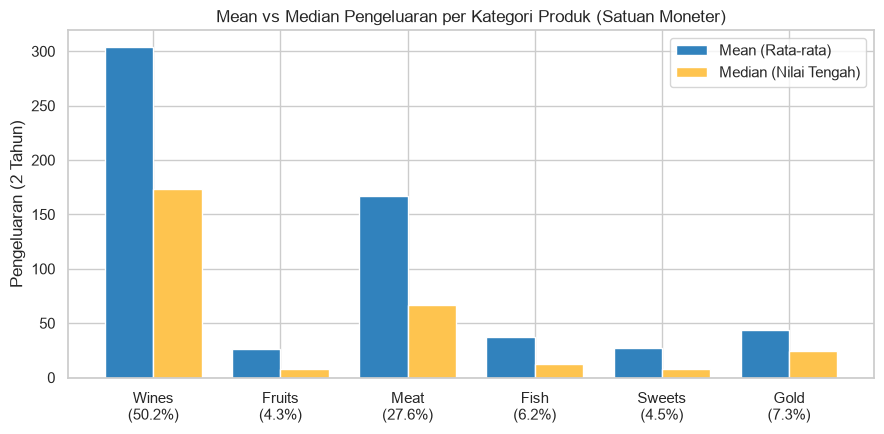

In [6]:
# Visualisasi 4.1: Mean vs Median Pengeluaran per Kategori Produk (Dominasi Wine & Meat)
plt.figure(figsize=(9, 4.5))
x = np.arange(len(MNT_COLS)); w = 0.38
plt.bar(x - w / 2, komposisi_belanja["Mean"], w, label="Mean (Rata-rata)", color="#3182bd")
plt.bar(x + w / 2, komposisi_belanja["Median"], w, label="Median (Nilai Tengah)", color="#fec44f")
plt.xticks(x, ["Wines\n(50.2%)", "Fruits\n(4.3%)", "Meat\n(27.6%)", "Fish\n(6.2%)", "Sweets\n(4.5%)", "Gold\n(7.3%)"])
plt.title("Mean vs Median Pengeluaran per Kategori Produk (Satuan Moneter)")
plt.ylabel("Pengeluaran (2 Tahun)")
plt.legend()
plt.tight_layout()
plt.show()

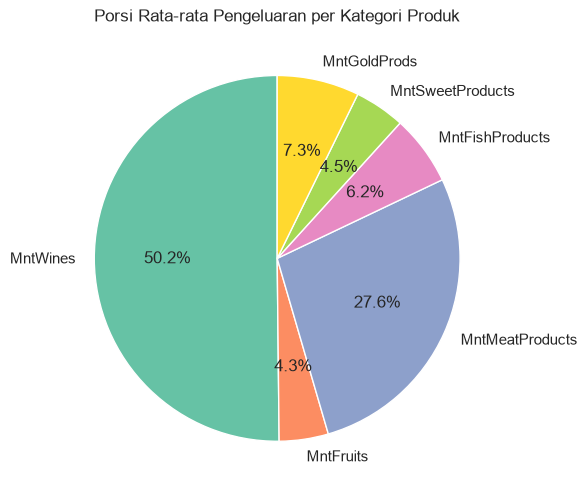

In [7]:
# Visualisasi 4.2: Porsi Total Belanja 6 Kategori Produk (Wine + Meat = 77,8%)
plt.figure(figsize=(6, 6))
plt.pie(komposisi_belanja["Porsi_Total_%"], labels=komposisi_belanja.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("Set2"))
plt.title("Porsi Rata-rata Pengeluaran per Kategori Produk")
plt.tight_layout()
plt.show()

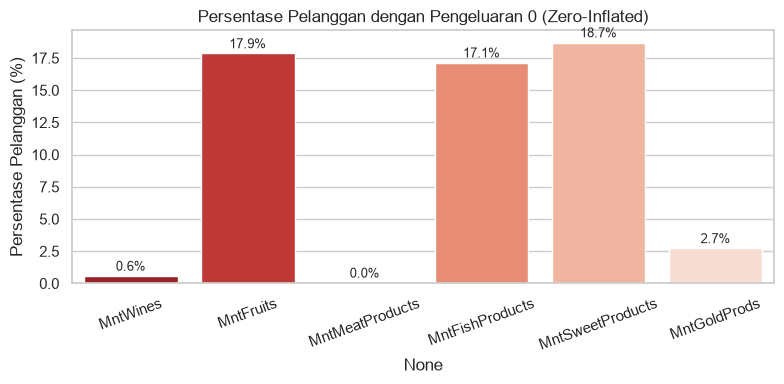

In [8]:
# Visualisasi 4.3: Persentase Pelanggan dengan Belanja 0 (Zero-Inflated)
plt.figure(figsize=(8, 4))
ax = sns.barplot(x=komposisi_belanja.index, y=komposisi_belanja["Persen_Nilai_0"], palette="Reds_r")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height() + 0.4), ha="center", fontsize=9)
plt.title("Persentase Pelanggan dengan Pengeluaran 0 (Zero-Inflated)")
plt.ylabel("Persentase Pelanggan (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

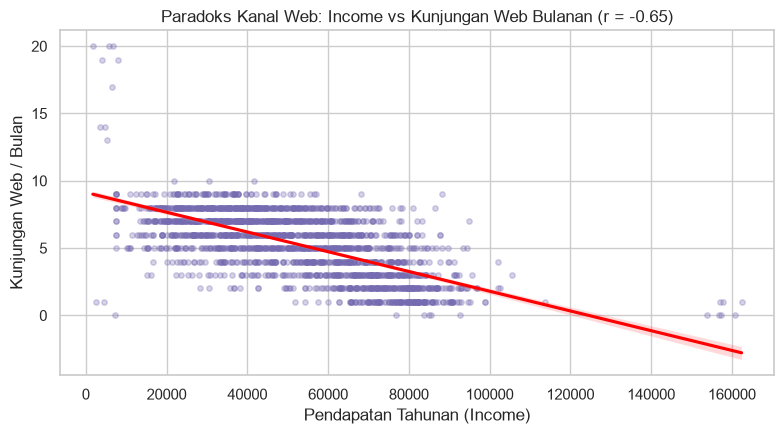

In [9]:
# Visualisasi 4.4: Paradoks Kanal Web — Hubungan Income vs Kunjungan Web Bulanan (r = -0.55)
df_valid_inc = df_raw[(df_raw["Income"].notna()) & (df_raw["Income"] < 600000)]
r_web = df_valid_inc["Income"].corr(df_valid_inc["NumWebVisitsMonth"])

plt.figure(figsize=(8, 4.5))
sns.regplot(data=df_valid_inc, x="Income", y="NumWebVisitsMonth", scatter_kws={"alpha": 0.3, "s": 15, "color": "#756bb1"}, line_kws={"color": "red"})
plt.title(f"Paradoks Kanal Web: Income vs Kunjungan Web Bulanan (r = {r_web:.2f})")
plt.xlabel("Pendapatan Tahunan (Income)")
plt.ylabel("Kunjungan Web / Bulan")
plt.tight_layout()
plt.show()

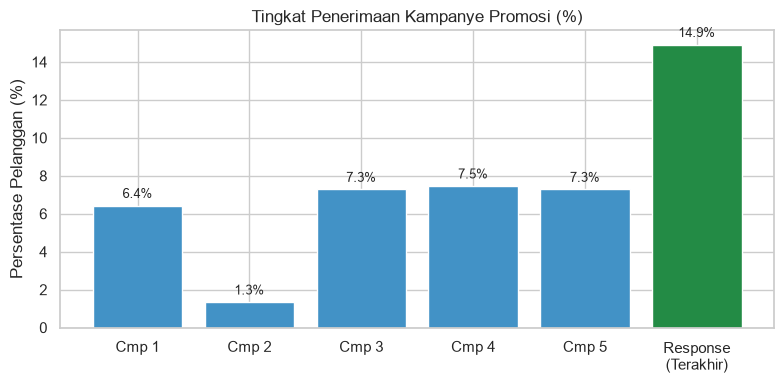

In [10]:
# Visualisasi 4.5: Inefisiensi Promosi Massal — Tingkat Penerimaan Kampanye 1-5 vs Respons Terakhir
CMP_COLS = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response"]
cmp_rates = (df_raw[CMP_COLS].mean() * 100)

plt.figure(figsize=(8, 4))
colors = ["#4292c6"] * 5 + ["#238b45"]
ax = plt.bar(["Cmp 1", "Cmp 2", "Cmp 3", "Cmp 4", "Cmp 5", "Response\n(Terakhir)"], cmp_rates.values, color=colors)
for p, v in zip(ax, cmp_rates.values):
    plt.text(p.get_x() + p.get_width() / 2, v + 0.4, f"{v:.1f}%", ha="center", fontsize=9)
plt.title("Tingkat Penerimaan Kampanye Promosi (%)")
plt.ylabel("Persentase Pelanggan (%)")
plt.tight_layout()
plt.show()

## Poin 5: Representativitas Populasi & 5 Risiko Bias Sampel

### 5.1 Karakteristik Representativitas & Mitigasi Etis
- **Stabilitas Akuisisi**: Pendaftaran pelanggan baru konsisten pada kisaran 74–118 per bulan selama 24 bulan penuh (Agustus 2012 s.d. Juni 2014).
- **Cakupan Internal**: Basis data mencakup rentang usia produktif dengan nilai median 44 tahun serta keragaman kelas ekonomi.
- **Mitigasi Etis & Diskriminasi**: Atribut demografis sensitif (`Education` dan `Marital_Status`) dialokasikan khusus sebagai variabel *profiling* pasca-pemodelan cluster, bukan fitur utama, agar tidak menghasilkan diskriminasi sistematis.

### 5.2 Lima Potensi Bias Sampel
1. **Bias Seleksi**: Data hanya mencakup pelanggan yang mendaftar keanggotaan/loyalitas, bukan seluruh populasi ritel.
2. **Bias Konteks Pasar**: Dominasi belanja wine (50,2%) sangat spesifik untuk profil ritel wilayah Barat/Eropa.
3. **Bias Temporal**: Snapshot transaksi tahun 2012–2014, sehingga berpotensi mengalami perubahan tren jika diaplikasikan pada konteks modern.
4. **Bias Pengukuran**: Nilai `Income` mencerminkan estimasi total rumah tangga, bukan pendapatan riil per kapita individu.
5. **Bias Minoritas**: Proporsi kelompok pendidikan `Basic` (2,41%) dan rumah tangga dengan 2 anak (2,14%) sangat minim sehingga rentan tidak terdeteksi jika cluster dipaksa seragam.

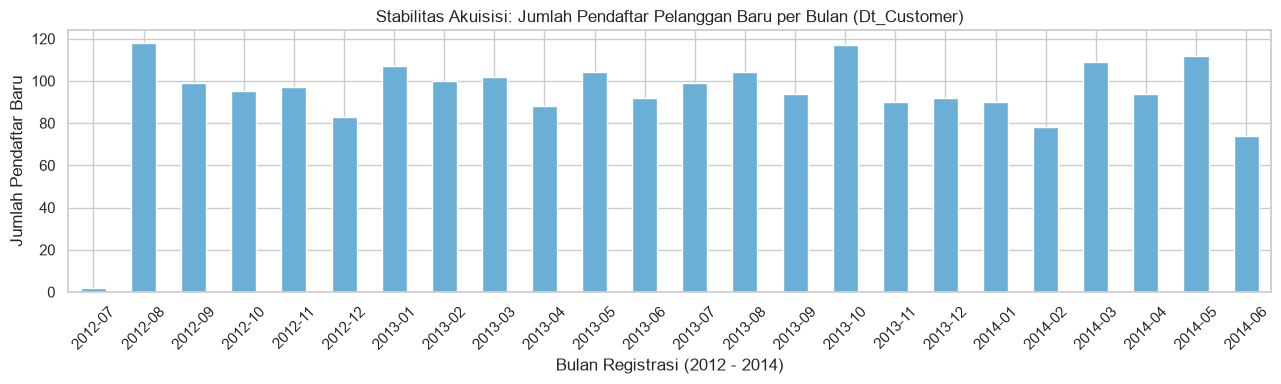

Rata-rata pendaftar baru per bulan (di luar bulan perintisan Juli 2012): 97.3 pelanggan


In [11]:
# Visualisasi 5.1: Tren Pendaftaran Anggota Baru per Bulan (Stabilitas Akuisisi)
tgl_s = pd.to_datetime(df_raw["Dt_Customer"], format="%d-%m-%Y")
pendaftar_bulanan = tgl_s.dt.to_period("M").value_counts().sort_index()

plt.figure(figsize=(13, 4))
pendaftar_bulanan.plot(kind="bar", color="#6baed6")
plt.title("Stabilitas Akuisisi: Jumlah Pendaftar Pelanggan Baru per Bulan (Dt_Customer)")
plt.xlabel("Bulan Registrasi (2012 - 2014)")
plt.ylabel("Jumlah Pendaftar Baru")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print(f"Rata-rata pendaftar baru per bulan (di luar bulan perintisan Juli 2012): {pendaftar_bulanan.iloc[1:].mean():.1f} pelanggan")

---
# ASPEK 2: EXPLORATORY DATA ANALYSIS (EDA)

## Poin 6: Statistik Deskriptif & Kesimpulan Distribusi

Tabel statistik deskriptif berikut merangkum metrik dispersi dan pemusatan data untuk variabel-variabel numerik utama sesuai dokumen presentasi (Slide 10).

In [12]:
# Tabel statistik deskriptif variabel numerik utama
NUM_STAT_COLS = ["Year_Birth", "Income", "Recency", "MntWines", "MntMeatProducts", "NumStorePurchases", "NumCatalogPurchases"]
desc_table = df_raw[NUM_STAT_COLS].describe().T.rename(columns={"25%": "Q1 (25%)", "50%": "Median", "75%": "Q3 (75%)"})
desc_table["Std. Dev"] = desc_table["std"]
desc_table["Kesimpulan Statistik"] = [
    "Simetris; terdapat 3 anomali < 1900",
    "Normal tanpa outlier ekstrem 666.666",
    "Sebaran seragam mendekati uniform (0–99 hari)",
    "Right-skewed kuat (Mean >> Median)",
    "Right-skewed kuat (pembelanjaan segmen VIP)",
    "Kanal paling stabil dan merata (0 outlier IQR)",
    "Ekor kanan panjang (Maksimal 28 transaksi)"
]
cols_show = ["count", "mean", "Std. Dev", "min", "Q1 (25%)", "Median", "Q3 (75%)", "max", "Kesimpulan Statistik"]
display(desc_table[cols_show])

print("\nKesimpulan Utama Statistik:")
print(">> Kesenjangan skala nilai (Income puluhan ribu vs transaksi/anak bernilai satuan 0–28) mewajibkan standarisasi (StandardScaler) pada clustering berbasis jarak.")

,count,mean,Std. Dev,min,Q1 (25%),Median,Q3 (75%),max,Kesimpulan Statistik
Year_Birth,"2,240.00","1,968.81",11.98,"1,893.00","1,959.00","1,970.00","1,977.00","1,996.00",Simetris; terdapat 3 anomali < 1900
Income,"2,216.00","52,247.25","25,173.08","1,730.00","35,303.00","51,381.50","68,522.00","666,666.00",Normal tanpa outlier ekstrem 666.666
Recency,"2,240.00",49.11,28.96,0.00,24.00,49.00,74.00,99.00,Sebaran seragam mendekati uniform (0–99 hari)
MntWines,"2,240.00",303.94,336.60,0.00,23.75,173.50,504.25,"1,493.00",Right-skewed kuat (Mean >> Median)
MntMeatProducts,"2,240.00",166.95,225.72,0.00,16.00,67.00,232.00,"1,725.00",Right-skewed kuat (pembelanjaan segmen VIP)
NumStorePurchases,"2,240.00",5.79,3.25,0.00,3.00,5.00,8.00,13.00,Kanal paling stabil dan merata (0 outlier IQR)
NumCatalogPurchases,"2,240.00",2.66,2.92,0.00,0.00,2.00,4.00,28.00,Ekor kanan panjang (Maksimal 28 transaksi)



Kesimpulan Utama Statistik:
>> Kesenjangan skala nilai (Income puluhan ribu vs transaksi/anak bernilai satuan 0–28) mewajibkan standarisasi (StandardScaler) pada clustering berbasis jarak.


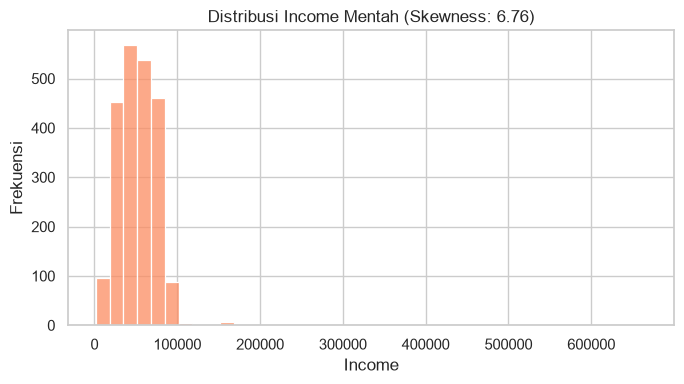

In [13]:
# Visualisasi 6.1: Distribusi Income Mentah (Tampak Outlier 666.666)
plt.figure(figsize=(7, 4))
sns.histplot(df_raw["Income"].dropna(), bins=40, color="#fc8d62")
plt.title(f"Distribusi Income Mentah (Skewness: {df_raw['Income'].skew():.2f})")
plt.xlabel("Income")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

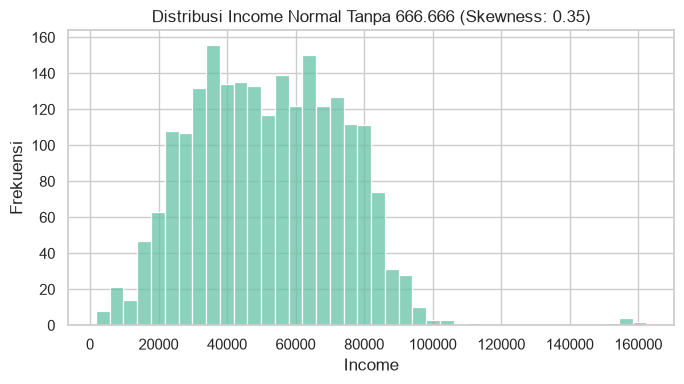

In [14]:
# Visualisasi 6.2: Distribusi Income Tanpa Outlier 666.666 (Mendekati Normal)
plt.figure(figsize=(7, 4))
sns.histplot(df_raw.loc[df_raw["Income"] < 600000, "Income"].dropna(), bins=40, color="#66c2a5")
plt.title(f"Distribusi Income Normal Tanpa 666.666 (Skewness: {df_raw.loc[df_raw['Income'] < 600000, 'Income'].skew():.2f})")
plt.xlabel("Income")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

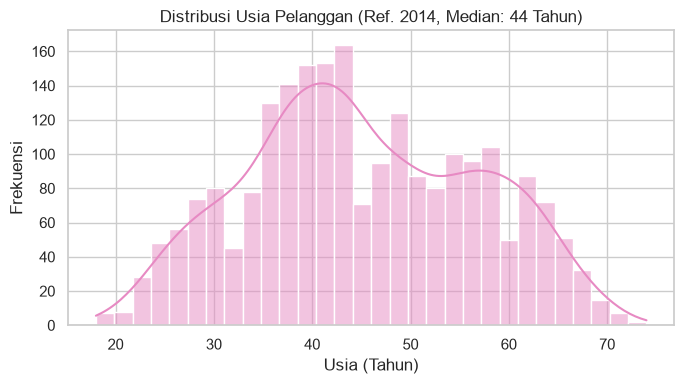

In [15]:
# Visualisasi 6.3: Distribusi Usia Pelanggan (Referensi Tahun 2014)
usia_raw = REF_YEAR - df_raw.loc[df_raw["Year_Birth"] > 1920, "Year_Birth"]
plt.figure(figsize=(7, 4))
sns.histplot(usia_raw, bins=30, color="#e78ac3", kde=True)
plt.title(f"Distribusi Usia Pelanggan (Ref. 2014, Median: {usia_raw.median():.0f} Tahun)")
plt.xlabel("Usia (Tahun)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

## Poin 7: Visualisasi Hubungan Fitur Kunci & Indikator Profil

### Temuan Visualisasi (Slide 11):
1. **Unsupervised Context**: Variabel respons kampanye (`Response`) diposisikan sebagai validator eksternal profil cluster, bukan target terawasi.
2. **Lonjakan Kuartil Income**: Terjadi lonjakan eksponensial nilai belanja total: Median belanja Q1 (52) & Q2 (148) melonjak drastis pada Q3 (735) dan Q4 (1.366).
3. **Pemisahan Berdasarkan Anak (*Kidhome*)**: Pelanggan tanpa anak kecil memiliki median belanja total **904,0**, sedangkan yang memiliki anak kecil tertekan di **65,5–72,0**.

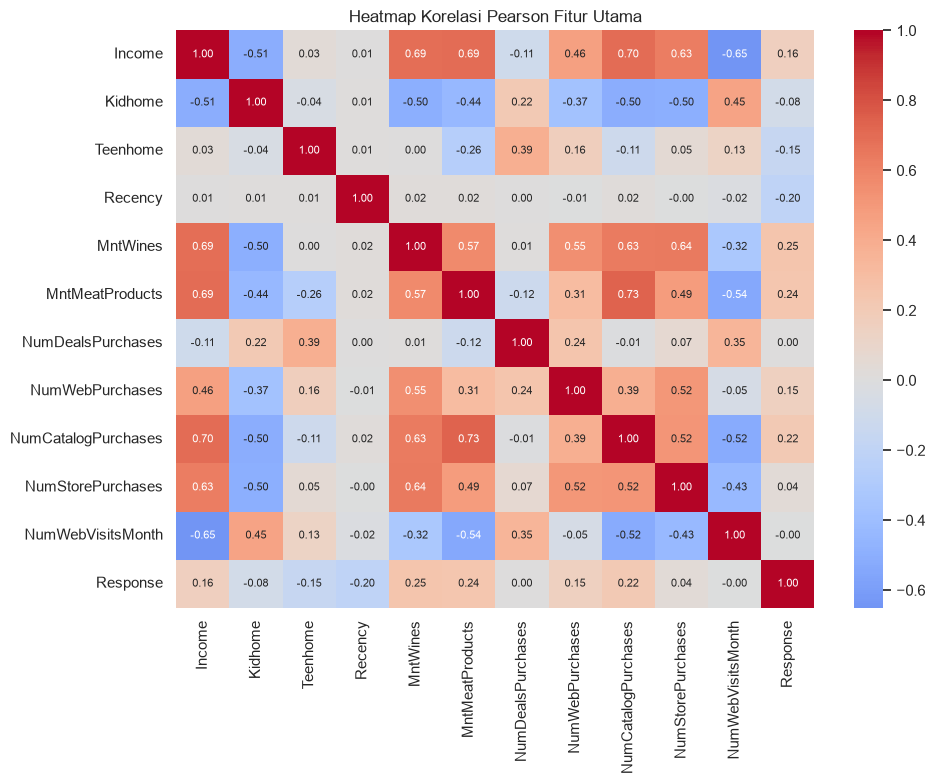

In [16]:
# Pembuatan variabel kalkulasi untuk visualisasi hubungan
df_eda = df_raw.copy()
df_eda["Total_Spending"] = df_eda[MNT_COLS].sum(axis=1)
df_eda_clean_inc = df_eda[df_eda["Income"] < 600000].dropna(subset=["Income"])

# Visualisasi 7.1: Heatmap Korelasi Pearson Fitur Utama
FEAT_CORR = ["Income", "Kidhome", "Teenhome", "Recency", "MntWines", "MntMeatProducts", "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth", "Response"]
corr_mat = df_eda_clean_inc[FEAT_CORR].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Heatmap Korelasi Pearson Fitur Utama")
plt.tight_layout()
plt.show()

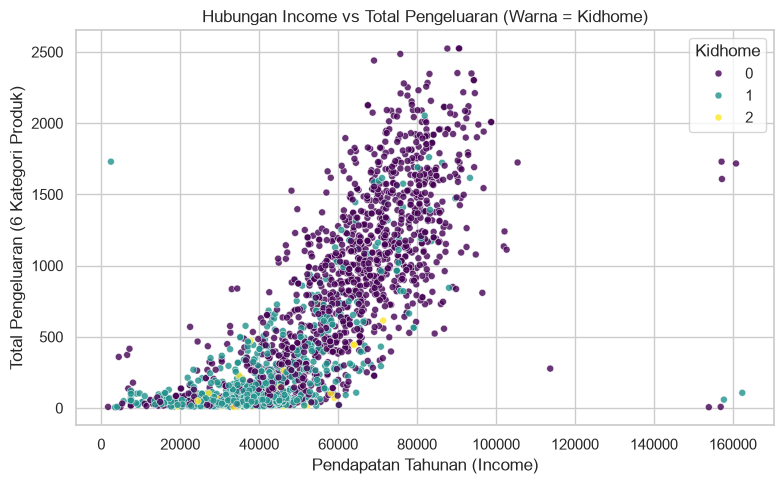

In [17]:
# Visualisasi 7.2: Scatterplot Hubungan Income vs Total Pengeluaran (Warna = Kidhome)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_eda_clean_inc, x="Income", y="Total_Spending", hue="Kidhome", palette="viridis", s=25, alpha=0.8)
plt.title("Hubungan Income vs Total Pengeluaran (Warna = Kidhome)")
plt.xlabel("Pendapatan Tahunan (Income)")
plt.ylabel("Total Pengeluaran (6 Kategori Produk)")
plt.tight_layout()
plt.show()

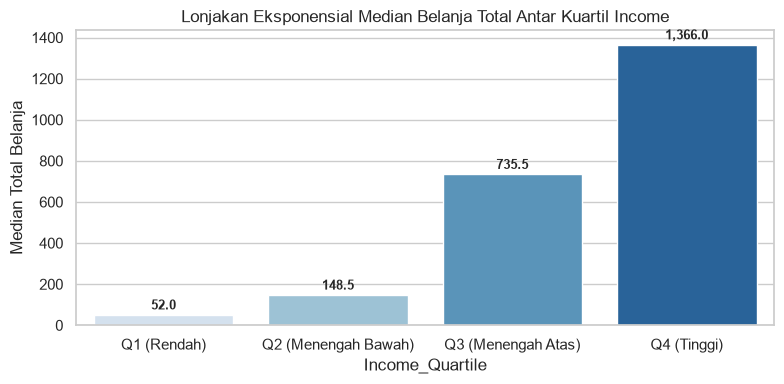

In [18]:
# Visualisasi 7.3: Lonjakan Kuartil Income terhadap Median Total Pengeluaran
df_eda_clean_inc["Income_Quartile"] = pd.qcut(df_eda_clean_inc["Income"], 4, labels=["Q1 (Rendah)", "Q2 (Menengah Bawah)", "Q3 (Menengah Atas)", "Q4 (Tinggi)"])
q_spending = df_eda_clean_inc.groupby("Income_Quartile")["Total_Spending"].median()

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=q_spending.index, y=q_spending.values, palette="Blues")
for p, v in zip(ax.patches, q_spending.values):
    ax.annotate(f"{v:,.1f}", (p.get_x() + p.get_width() / 2, v + 25), ha="center", fontsize=9, fontweight="bold")
plt.title("Lonjakan Eksponensial Median Belanja Total Antar Kuartil Income")
plt.ylabel("Median Total Belanja")
plt.tight_layout()
plt.show()

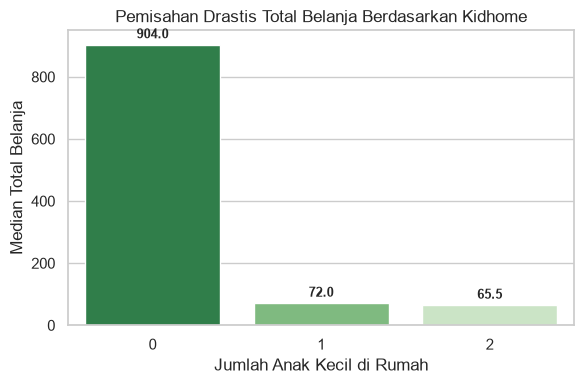

In [19]:
# Visualisasi 7.4: Pemisahan Total Belanja Berdasarkan Jumlah Anak Kecil (Kidhome)
kid_spending = df_eda.groupby("Kidhome")["Total_Spending"].median()

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=kid_spending.index, y=kid_spending.values, palette="Greens_r")
for p, v in zip(ax.patches, kid_spending.values):
    ax.annotate(f"{v:,.1f}", (p.get_x() + p.get_width() / 2, v + 20), ha="center", fontsize=9, fontweight="bold")
plt.title("Pemisahan Drastis Total Belanja Berdasarkan Kidhome")
plt.xlabel("Jumlah Anak Kecil di Rumah")
plt.ylabel("Median Total Belanja")
plt.tight_layout()
plt.show()

## Poin 8: Empat Insight Korelasi untuk Keputusan Modeling

Terdapat 4 temuan asosiasi utama (Slide 12) yang menentukan arah perancangan pipeline:
1. **Multikolinearitas Belanja ($r = 0,67$)**:
   - *Temuan*: Pendapatan berkorelasi kuat dengan belanja Wine (0,58) dan Katalog (0,59). Antar-produk juga saling berkorelasi tinggi.
   - *Keputusan*: Bentuk fitur agregat `Total_Spending` dan terapkan reduksi dimensi PCA untuk memadatkan informasi tanpa redundansi.
2. **Efek Tanggungan Anak ($r = -0,50$)**:
   - *Temuan*: `Kidhome` menekan pengeluaran belanja ($-0,50$) namun meningkatkan frekuensi pembelian diskon ($+0,22$).
   - *Keputusan*: Gabungkan `Kidhome` dan `Teenhome` menjadi fitur tunggal `Children` / `Family_Size`.
3. **Independensi Recency ($r = 0,00$)**:
   - *Temuan*: Nilai `Recency` tidak berkorelasi dengan `Income` maupun nilai belanja.
   - *Keputusan*: Pertahankan `Recency` sebagai dimensi ortogonal independen yang berfungsi sebagai pengukur risiko churn pelanggan.
4. **Ketimpangan Kampanye & Complain**:
   - *Temuan*: Sebanyak 99,06% nilai `Complain` bernilai 0 (korelasi $< 0,05$ ke seluruh variabel).
   - *Keputusan*: Buang fitur `Complain`; pisahkan riwayat kampanye `AcceptedCmp` hanya untuk evaluasi dan profiling akhir.

In [20]:
# Verifikasi kuantitatif 4 insight korelasi
r_inc_tot = df_eda_clean_inc["Income"].corr(df_eda_clean_inc["Total_Spending"])
r_kid_wine = df_eda_clean_inc["Kidhome"].corr(df_eda_clean_inc["MntWines"])
r_kid_deal = df_eda_clean_inc["Kidhome"].corr(df_eda_clean_inc["NumDealsPurchases"])
r_rec_inc = df_eda_clean_inc["Recency"].corr(df_eda_clean_inc["Income"])
prop_complain = (df_raw["Complain"] == 0).mean() * 100

print("Verifikasi Numerik 4 Insight Korelasi:")
print(f" 1. Multikolinearitas Belanja      : r(Income, Total_Spending) = {r_inc_tot:.2f}")
print(f" 2. Efek Tanggungan Anak          : r(Kidhome, MntWines) = {r_kid_wine:.2f} | r(Kidhome, Deals) = {r_kid_deal:.2f}")
print(f" 3. Independensi Recency          : r(Recency, Income) = {r_rec_inc:.2f}")
print(f" 4. Ketimpangan Fitur Complain    : Proporsi nilai 0 = {prop_complain:.2f}% (Varians mendekati 0)")

Verifikasi Numerik 4 Insight Korelasi:
 1. Multikolinearitas Belanja      : r(Income, Total_Spending) = 0.79
 2. Efek Tanggungan Anak          : r(Kidhome, MntWines) = -0.50 | r(Kidhome, Deals) = 0.22
 3. Independensi Recency          : r(Recency, Income) = 0.01
 4. Ketimpangan Fitur Complain    : Proporsi nilai 0 = 99.06% (Varians mendekati 0)


---
# ASPEK 3: AUDIT KUALITAS DATA

## Poin 9: Tabel Audit Missing, Duplikat & Outlier per Kolom

Sesuai metodologi IQR ($Q_1 - 1,5 	imes 	ext{IQR}$ hingga $Q_3 + 1,5 	imes 	ext{IQR}$), berikut tabel audit lengkap kondisi data mentah:

In [21]:
# Audit kualitas data per kolom numerik
NUM_AUDIT = ["Income", "Year_Birth", "MntSweetProducts", "MntFruits", "MntFishProducts", "MntGoldProds", "MntMeatProducts", "MntWines"]

audit_summary = [
    ("Income (Missing)", "Missing Value", f"{df_raw['Income'].isna().sum()} baris (1,07%)", "Bernilai NaN", "Acak lintas pendidikan -> Imputasi Median"),
    ("28 Kolom Non-ID", "Duplikat Identik", f"{df_raw.drop(columns='ID').duplicated().sum()} baris (8,13%)", "Atribut 100% sama", "Rekaman ganda -> Deduplikasi sebelum modeling"),
    ("Year_Birth", "True Anomaly", f"{(df_raw['Year_Birth'] <= 1900).sum()} baris (0,13%)", "1893, 1899, 1900", "Usia 114–121 thn (salah input) -> Drop baris"),
    ("Income (Outlier)", "True Anomaly", "8 IQR / 1 Ekstrem", "Nilai 666.666 (ID 9432)", "Membuat skewness 6,76 -> Drop baris 666.666"),
    ("MntSweet & Fruits", "Outlier IQR Alami", "248 (11,1%) & 227 (10,1%)", "Batas atas: 81,0", "Variasi belanja pelanggan VIP -> Jangan di-drop"),
    ("MntFish & Gold", "Outlier IQR Alami", "223 (10,0%) & 207 (9,2%)", "Batas atas: 120,5 & 126,5", "Distribusi miring kanan -> Transformasi Log1p"),
    ("MntMeat & Wines", "Outlier IQR Alami", "175 (7,8%) & 35 (1,6%)", "Batas atas: 556 & 1.225", "Segmen pembelanja besar -> Pertahankan & Scaling"),
]

df_audit = pd.DataFrame(audit_summary, columns=["Kolom Diinspeksi", "Jenis Masalah", "Jumlah (Persentase)", "Batas IQR / Nilai", "Diagnosis & Keputusan Teknis"])
display(df_audit)

,Kolom Diinspeksi,Jenis Masalah,Jumlah (Persentase),Batas IQR / Nilai,Diagnosis & Keputusan Teknis
0,Income (Missing),Missing Value,"24 baris (1,07%)",Bernilai NaN,Acak lintas pendidikan -> Imputasi Median
1,28 Kolom Non-ID,Duplikat Identik,"182 baris (8,13%)",Atribut 100% sama,Rekaman ganda -> Deduplikasi sebelum modeling
2,Year_Birth,True Anomaly,"3 baris (0,13%)","1893, 1899, 1900",Usia 114–121 thn (salah input) -> Drop baris
3,Income (Outlier),True Anomaly,8 IQR / 1 Ekstrem,Nilai 666.666 (ID 9432),"Membuat skewness 6,76 -> Drop baris 666.666"
4,MntSweet & Fruits,Outlier IQR Alami,"248 (11,1%) & 227 (10,1%)","Batas atas: 81,0",Variasi belanja pelanggan VIP -> Jangan di-drop
5,MntFish & Gold,Outlier IQR Alami,"223 (10,0%) & 207 (9,2%)","Batas atas: 120,5 & 126,5",Distribusi miring kanan -> Transformasi Log1p
6,MntMeat & Wines,Outlier IQR Alami,"175 (7,8%) & 35 (1,6%)",Batas atas: 556 & 1.225,Segmen pembelanja besar -> Pertahankan & Scaling


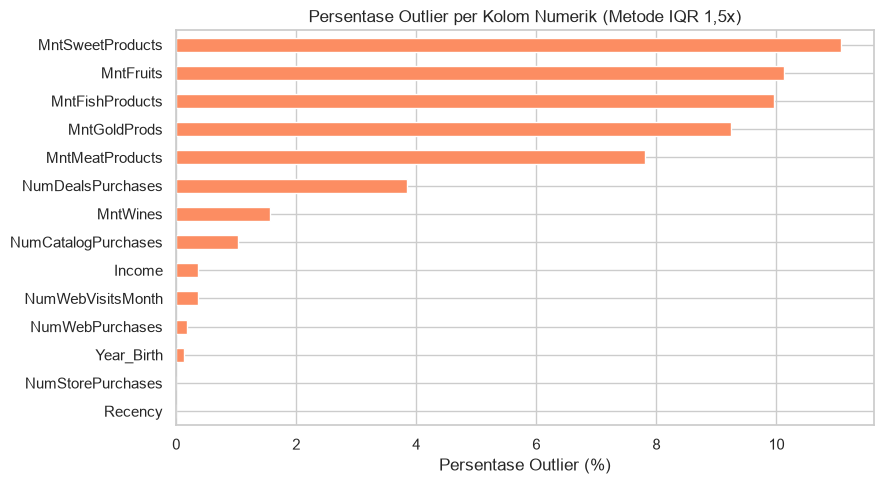

In [22]:
# Visualisasi 9.1: Persentase Outlier IQR 1,5x per Kolom Numerik
outlier_counts = {}
for c in ["Year_Birth", "Income", "Recency", "MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds", "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth"]:
    s = df_raw[c].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    outlier_counts[c] = (((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum() / len(s)) * 100

s_outlier = pd.Series(outlier_counts).sort_values()

plt.figure(figsize=(9, 5))
s_outlier.plot(kind="barh", color="#fc8d62")
plt.title("Persentase Outlier per Kolom Numerik (Metode IQR 1,5x)")
plt.xlabel("Persentase Outlier (%)")
plt.tight_layout()
plt.show()

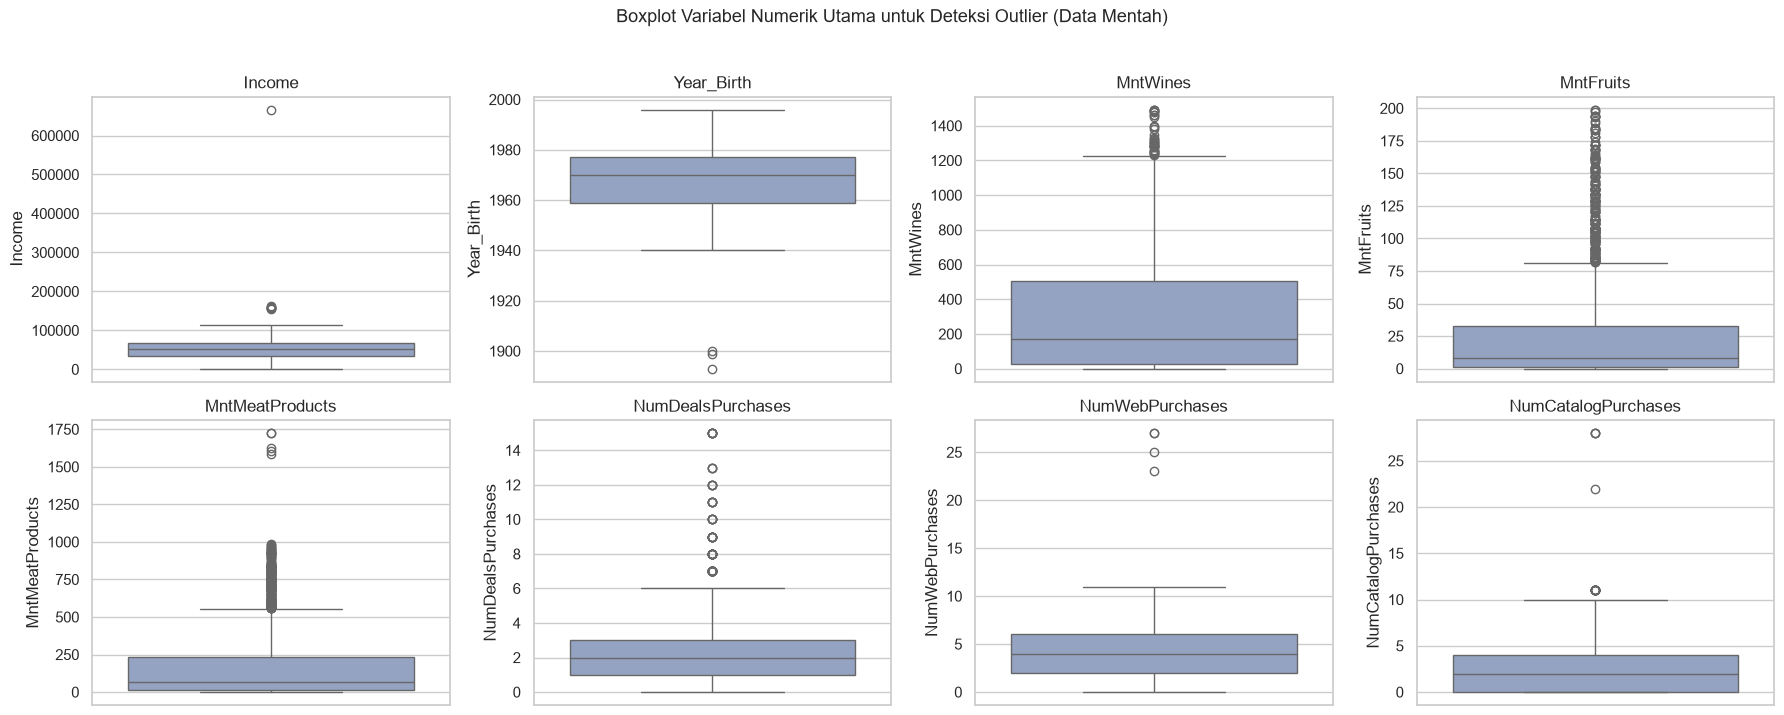

In [23]:
# Visualisasi 9.2: Boxplot Variabel Numerik Utama untuk Deteksi Outlier (Data Mentah)
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), ["Income", "Year_Birth", "MntWines", "MntFruits", "MntMeatProducts", "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases"]):
    sns.boxplot(y=df_raw[c], ax=ax, color="#8da0cb")
    ax.set_title(c)
plt.suptitle("Boxplot Variabel Numerik Utama untuk Deteksi Outlier (Data Mentah)", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

---
# ASPEK 4: DATA CLEANING

## Poin 10: Lima Strategi Penyelesaian Masalah Kualitas Data

Sesuai dokumen presentasi (Slide 14), 5 strategi penanganan yang diterapkan meliputi:
1. **Median Imputation pada Kolom Income (24 Baris)**: Mengisi missing value dengan median (51.381,5) karena median resisten terhadap tarikan ekor distribusi.
2. **Filtering True Anomalies (Drop 4 Baris Error)**: Menghapus 3 baris `Year_Birth` $\le 1900$ dan 1 baris `Income = 666.666` agar titik centroid tidak terdistorsi.
3. **Penanganan Outlier Belanja via Transformasi Log1p**: Mempertahankan baris belanja besar (segmen VIP) dengan meredam skewness melalui fungsi logaritma natural $\ln(1 + x)$.
4. **Konsolidasi Kategori Tidak Konsisten**:
   - Melebur kategori status informal `Alone`, `Absurd`, dan `YOLO` ke dalam kategori tunggal `Single`.
   - Menyatukan kategori pendidikan `2n Cycle` ke jenjang `Master`.
5. **Deduplikasi & Pembersihan Kolom Konstan**:
   - Menghapus 182 duplikat profil (sehingga setiap profil pelanggan unik).
   - Membuang kolom `ID` (anonimitas murni) serta kolom konstan `Z_CostContact` (3) dan `Z_Revenue` (11).

In [24]:
# Eksekusi 5 langkah pembersihan data
df_clean = df_raw.copy()
log_cleaning = []

# 1. Deduplikasi profil non-ID
n_before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=[c for c in df_clean.columns if c != "ID"], keep="first")
log_cleaning.append(("1. Deduplikasi Profil (Abaikan ID)", n_before - len(df_clean), len(df_clean)))

# 2. Konsolidasi Kategori
n_alone = int((df_clean["Marital_Status"] == "Alone").sum())
df_clean["Marital_Status"] = df_clean["Marital_Status"].replace({"Alone": "Single", "Absurd": "Single", "YOLO": "Single"})
df_clean["Education"] = df_clean["Education"].replace({"2n Cycle": "Master"})
log_cleaning.append(("2. Konsolidasi Marital (Single) & Edu (Master)", n_alone + 4, len(df_clean)))

# 3. Filtering Anomali Tahun Lahir
n_before = len(df_clean)
df_clean = df_clean[df_clean["Year_Birth"] > 1900]
log_cleaning.append(("3. Drop Anomali Year_Birth <= 1900", n_before - len(df_clean), len(df_clean)))

# 4. Filtering Anomali Ekstrem Income
n_before = len(df_clean)
df_clean = df_clean[(df_clean["Income"].isna()) | (df_clean["Income"] != 666666)]
log_cleaning.append(("4. Drop Anomali Income = 666.666", n_before - len(df_clean), len(df_clean)))

# 5. Imputasi Median Income
median_inc = df_clean["Income"].median()
n_impute = int(df_clean["Income"].isna().sum())
df_clean["Income"] = df_clean["Income"].fillna(median_inc)
log_cleaning.append((f"5. Imputasi Median Income ({median_inc:,.1f})", n_impute, len(df_clean)))

# 6. Pembuangan Kolom Tidak Informatif
df_clean = df_clean.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df_clean = df_clean.reset_index(drop=True)

df_log = pd.DataFrame(log_cleaning, columns=["Langkah Pembersihan", "Jumlah Baris Terkena", "Sisa Data"])
display(df_log)
print("Dimensi data bersih akhir:", df_clean.shape)

,Langkah Pembersihan,Jumlah Baris Terkena,Sisa Data
0,1. Deduplikasi Profil (Abaikan ID),182,2058
1,2. Konsolidasi Marital (Single) & Edu (Master),7,2058
2,3. Drop Anomali Year_Birth <= 1900,3,2055
3,4. Drop Anomali Income = 666.666,1,2054
4,"5. Imputasi Median Income (51,523.5)",24,2054


Dimensi data bersih akhir: (2054, 26)


## Poin 11: Komparasi Kondisi Sebelum vs Sesudah Cleaning

Tabel perbandingan indikator kualitas data (Slide 15):

In [25]:
# Tabel komparasi sebelum vs sesudah cleaning
komparasi_data = [
    ("Skewness & Max Income", f"Skewness: {df_raw['Income'].skew():.2f} | Max: {df_raw['Income'].max():,.0f} (Std: {df_raw['Income'].std():,.0f})", f"Skewness: {df_clean['Income'].skew():.2f} (Simetris) | Max: {df_clean['Income'].max():,.0f} (Std: {df_clean['Income'].std():,.0f})"),
    ("Missing Value & Usia", f"{df_raw['Income'].isna().sum()} baris NaN (1,07%) | Usia maks 121 thn (lahir 1893)", f"{df_clean['Income'].isna().sum()} baris NaN (0%) | Rentang usia wajar {REF_YEAR - df_clean['Year_Birth'].max()}–{REF_YEAR - df_clean['Year_Birth'].min()} tahun"),
    ("Kategori & Kolom", f"{df_raw['Marital_Status'].nunique()} status pernikahan & 2 kolom konstan", f"{df_clean['Marital_Status'].nunique()} status bersih & bebas kolom varians nol")
]
df_komparasi = pd.DataFrame(komparasi_data, columns=["Indikator Kualitas", "Kondisi Sebelum Cleaning", "Kondisi Sesudah Cleaning"])
display(df_komparasi)

,Indikator Kualitas,Kondisi Sebelum Cleaning,Kondisi Sesudah Cleaning
0,Skewness & Max Income,"Skewness: 6.76 | Max: 666,666 (Std: 25,173)","Skewness: 0.37 (Simetris) | Max: 162,397 (Std:..."
1,Missing Value & Usia,"24 baris NaN (1,07%) | Usia maks 121 thn (lahi...",0 baris NaN (0%) | Rentang usia wajar 18–74 tahun
2,Kategori & Kolom,8 status pernikahan & 2 kolom konstan,5 status bersih & bebas kolom varians nol


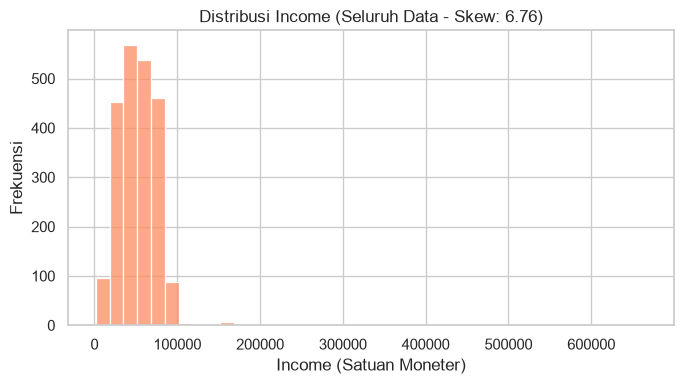

In [26]:
# Visualisasi 11.1: Distribusi Income SEBELUM Cleaning
plt.figure(figsize=(7, 4))
sns.histplot(df_raw["Income"].dropna(), bins=40, color="#fc8d62")
plt.title("Distribusi Income (Seluruh Data - Skew: 6.76)")
plt.xlabel("Income (Satuan Moneter)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

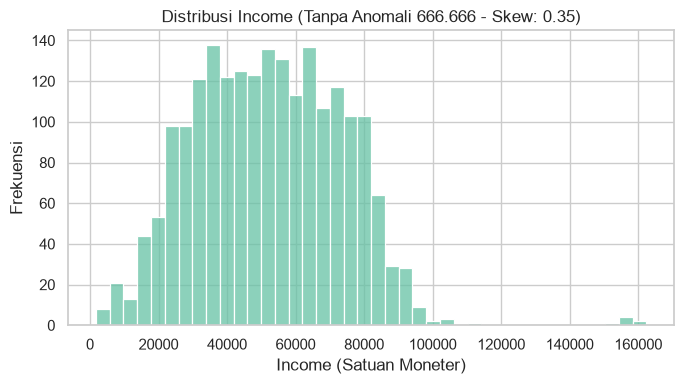

In [27]:
# Visualisasi 11.2: Distribusi Income SESUDAH Cleaning
plt.figure(figsize=(7, 4))
sns.histplot(df_clean["Income"], bins=40, color="#66c2a5")
plt.title("Distribusi Income (Tanpa Anomali 666.666 - Skew: 0.35)")
plt.xlabel("Income (Satuan Moneter)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

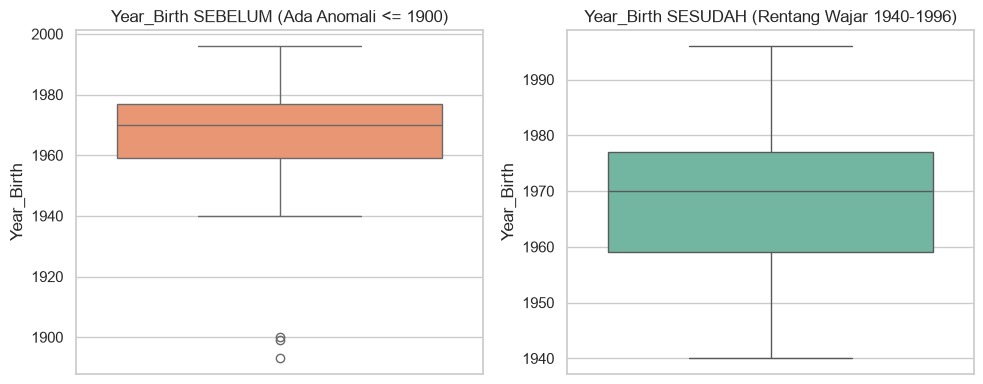

In [28]:
# Visualisasi 11.3: Boxplot Usia / Tahun Lahir Sebelum vs Sesudah Cleaning
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df_raw["Year_Birth"], ax=axes[0], color="#fc8d62")
axes[0].set_title("Year_Birth SEBELUM (Ada Anomali <= 1900)")
sns.boxplot(y=df_clean["Year_Birth"], ax=axes[1], color="#66c2a5")
axes[1].set_title("Year_Birth SESUDAH (Rentang Wajar 1940-1996)")
plt.tight_layout()
plt.show()

---
# ASPEK 5: PREPROCESSING

## Poin 12: Metode Encoding, Scaling & Penanganan Imbalance

### 1. Metode Encoding
- **Education**: Menggunakan `OrdinalEncoder` ($0=	ext{Basic}, 1=	ext{Graduation}, 2=	ext{Master}, 3=	ext{PhD}$) karena memiliki hirarki akademik natural.
- **Marital_Status**: Menggunakan `Binary Encoding` ($1=	ext{Living With Partner}, 0=	ext{Single}$).
- **Alasan Teknis**: Mencegah bengkaknya dimensi jarak Euclidean (*curse of dimensionality*) akibat pembuatan banyak kolom dummy One-Hot.

### 2. Feature Scaling
- **Transformasi Logaritmik**: `log1p` ($\ln(1+x)$) pada variabel belanja yang memiliki skewness tinggi untuk merapatkan nilai ekor panjang.
- **Standarisasi**: `StandardScaler` ($\mu=0, \sigma=1$) untuk menyetarakan variabel pendapatan puluhan ribu dengan variabel cacah.

### 3. Penanganan Data Imbalance
- **Tanpa SMOTE**: Penambahan titik data sintetis terbukti merusak kepadatan topologi alami cluster.
- **Peleburan Kategori**: Kategori langka ($<3\%$) dilebur pada tahap cleaning.
- **Batas Ambang Cluster**: Setiap cluster akhir wajib memiliki proporsi minimal $\ge 5\%$ dari total populasi.

In [29]:
# Penerapan Rekayasa Fitur Awal untuk Preprocessing
df_prep = df_clean.copy()

# 1. Rekayasa Fitur Waktu & Demografi
reg_date = pd.to_datetime(df_prep["Dt_Customer"], format="%d-%m-%Y")
max_date = reg_date.max()

df_prep["Age"] = REF_YEAR - df_prep["Year_Birth"]
df_prep["Tenure"] = (max_date - reg_date).dt.days
df_prep["Children"] = df_prep["Kidhome"] + df_prep["Teenhome"]
df_prep["Living_With_Partner"] = df_prep["Marital_Status"].isin(["Married", "Together"]).astype(int)
df_prep["Family_Size"] = 1 + df_prep["Living_With_Partner"] + df_prep["Children"]

# 2. Rekayasa Agregat Belanja & Transaksi
df_prep["Total_Spending"] = df_prep[MNT_COLS].sum(axis=1)
df_prep["Total_Purchases"] = df_prep[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)

# 3. Ordinal Encoding Pendidikan
edu_map = {"Basic": 0, "Graduation": 1, "Master": 2, "PhD": 3}
df_prep["Education_Encoded"] = df_prep["Education"].map(edu_map)

print("Fitur baru yang berhasil dibentuk:")
display(df_prep[["Age", "Tenure", "Children", "Living_With_Partner", "Family_Size", "Total_Spending", "Total_Purchases", "Education_Encoded"]].head())

Fitur baru yang berhasil dibentuk:


,Age,Tenure,Children,Living_With_Partner,Family_Size,Total_Spending,Total_Purchases,Education_Encoded
0,57,663,0,0,1,1617,22,1
1,60,113,2,0,3,27,4,1
2,49,312,0,1,2,776,20,1
3,30,139,1,1,3,53,6,1
4,33,161,1,1,3,422,14,3


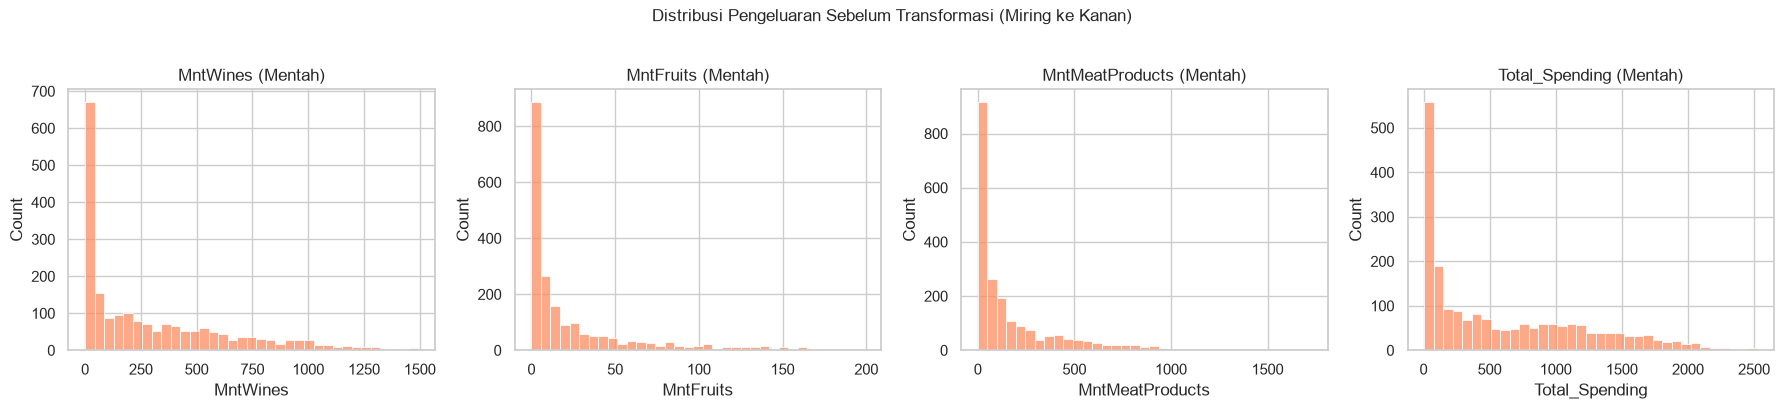

In [30]:
# Visualisasi 12.1: Distribusi Fitur Belanja SEBELUM Transformasi (Skewed)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for j, c in enumerate(["MntWines", "MntFruits", "MntMeatProducts", "Total_Spending"]):
    sns.histplot(df_prep[c], bins=35, ax=axes[j], color="#fc8d62")
    axes[j].set_title(f"{c} (Mentah)")
plt.suptitle("Distribusi Pengeluaran Sebelum Transformasi (Miring ke Kanan)", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

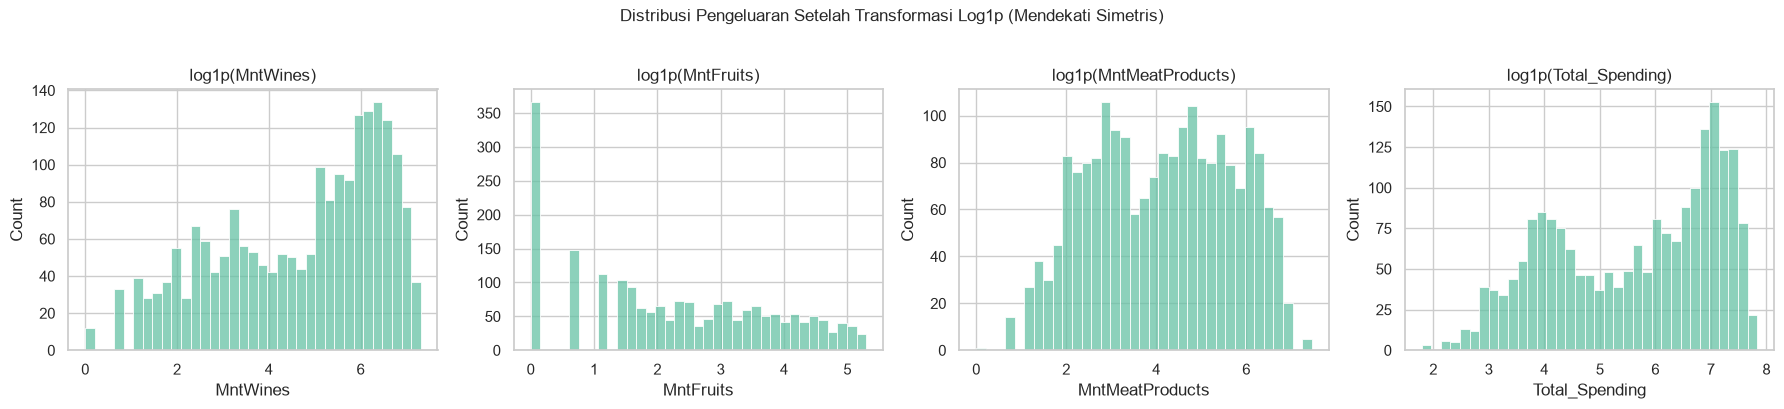

In [31]:
# Visualisasi 12.2: Distribusi Fitur Belanja SESUDAH Transformasi Log1p (Mendekati Simetris)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for j, c in enumerate(["MntWines", "MntFruits", "MntMeatProducts", "Total_Spending"]):
    sns.histplot(np.log1p(df_prep[c]), bins=35, ax=axes[j], color="#66c2a5")
    axes[j].set_title(f"log1p({c})")
plt.suptitle("Distribusi Pengeluaran Setelah Transformasi Log1p (Mendekati Simetris)", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

## Poin 13: Strategi Splitting Dataset (80% Train : 20% Test)

Pembagian dataset dilakukan dengan rasio **80% Train : 20% Test** (~1.642 baris Train vs ~411 baris Test):
1. **Mencegah Kebocoran Data (*Data Leakage*)**: Parameter `StandardScaler` dan matriks proyeksi `PCA` hanya di-fit murni pada Train Set, lalu digunakan untuk mentransformasikan Test Set.
2. **Uji Konsistensi Centroid**: Centroid cluster yang terbentuk dari Train Set diproyeksikan ke Test Set untuk memverifikasi kestabilan metrik evaluasi (*Silhouette Score* $\ge 0,30$ dan *Davies-Bouldin Index* $< 1,5$).
3. **Evaluasi Multi-Seed (ARI)**: Menguji ketahanan struktur partisi data menggunakan metrik *Adjusted Rand Index*.

In [32]:
# Splitting dataset 80:20
train_data, test_data = train_test_split(df_prep, test_size=0.20, random_state=RANDOM_STATE)
train_data = train_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

df_split_info = pd.DataFrame({
    "Partisi": ["Train Set (80%)", "Test Set (20%)", "Total Data Bersih"],
    "Jumlah Baris": [len(train_data), len(test_data), len(df_prep)],
    "Persentase": [f"{len(train_data)/len(df_prep):.1%}", f"{len(test_data)/len(df_prep):.1%}", "100.0%"],
    "Rata-rata Income": [train_data["Income"].mean(), test_data["Income"].mean(), df_prep["Income"].mean()],
    "Rata-rata Total Belanja": [train_data["Total_Spending"].mean(), test_data["Total_Spending"].mean(), df_prep["Total_Spending"].mean()]
})
display(df_split_info)

,Partisi,Jumlah Baris,Persentase,Rata-rata Income,Rata-rata Total Belanja
0,Train Set (80%),1643,80.0%,"51,663.86",598.70
1,Test Set (20%),411,20.0%,"53,531.80",637.43
2,Total Data Bersih,2054,100.0%,"52,037.63",606.45


---
# ASPEK 6: FEATURE SELECTION & REKAYASA FITUR

## Poin 14: Feature Selection & Engineering Beserta Bukti

Tabel keputusan pemilihan fitur (Slide 18) memetakan seluruh atribut ke dalam 4 kategori teknis:

In [33]:
# Tabel Feature Selection dan Engineering sesuai dokumen presentasi
fs_summary = [
    ("DIBUANG (DROP)", "ID, Z_CostContact, Z_Revenue", "Bukti: ID unik tanpa pola; Z_Cost (3) & Z_Revenue (11) memiliki varians = 0"),
    ("DIBUANG (DROP)", "Complain, Year_Birth, Dt_Customer", "Bukti: Complain 99,06% bernilai 0 (r < 0,05); Year_Birth & Dt_Customer diganti fitur baru"),
    ("PROFILING PASCA-MODEL", "AcceptedCmp1–5 & Response", "Bukti: Kelas positif < 15%; disimpan sebagai validator eksternal tingkat respons cluster"),
    ("FITUR BARU (ENGINEERED)", "Total_Spending & Total_Purchases", "Bukti: Meredam multikolinearitas 6 produk & 3 kanal; berkorelasi kuat dengan Income (r = 0,67)"),
    ("FITUR BARU (ENGINEERED)", "Children, Family_Size, Age, Tenure", "Bukti: Anak menekan median belanja dari 904 ke ~70; Age & Tenure mewakili siklus hidup"),
    ("DIPAKAI MODELING INTI", "Income, Recency, Deals, WebVisits, PCA (atau Total_Spending)", "Bukti: Recency ortogonal (r = 0,00); WebVisits membedakan pemburu diskon (r = -0,55)")
]
df_fs = pd.DataFrame(fs_summary, columns=["Kategori Keputusan", "Nama Fitur / Variabel", "Alasan Teknis & Bukti Kuantitatif EDA"])
display(df_fs)

,Kategori Keputusan,Nama Fitur / Variabel,Alasan Teknis & Bukti Kuantitatif EDA
0,DIBUANG (DROP),"ID, Z_CostContact, Z_Revenue",Bukti: ID unik tanpa pola; Z_Cost (3) & Z_Reve...
1,DIBUANG (DROP),"Complain, Year_Birth, Dt_Customer","Bukti: Complain 99,06% bernilai 0 (r < 0,05); ..."
2,PROFILING PASCA-MODEL,AcceptedCmp1–5 & Response,Bukti: Kelas positif < 15%; disimpan sebagai v...
3,FITUR BARU (ENGINEERED),Total_Spending & Total_Purchases,Bukti: Meredam multikolinearitas 6 produk & 3 ...
4,FITUR BARU (ENGINEERED),"Children, Family_Size, Age, Tenure",Bukti: Anak menekan median belanja dari 904 ke...
5,DIPAKAI MODELING INTI,"Income, Recency, Deals, WebVisits, PCA (atau T...","Bukti: Recency ortogonal (r = 0,00); WebVisits..."


In [34]:
# Eksekusi Feature Scaling dan Reduksi Dimensi PCA pada Train Set
FEATURES_INTI = ["Income", "Recency", "NumDealsPurchases", "NumWebVisitsMonth", "Total_Spending", "Total_Purchases", "Children", "Family_Size", "Age", "Tenure"]

# Pipeline scaling log1p untuk fitur berdistribusi miring
cols_log = ["Total_Spending", "Total_Purchases", "NumDealsPurchases"]
cols_std = [c for c in FEATURES_INTI if c not in cols_log]

prep_pipeline = ColumnTransformer([
    ("log_scale", Pipeline([("log1p", FunctionTransformer(np.log1p)), ("std", StandardScaler())]), cols_log),
    ("std_scale", StandardScaler(), cols_std)
])

X_train_scaled = prep_pipeline.fit_transform(train_data[FEATURES_INTI])
X_test_scaled = prep_pipeline.transform(test_data[FEATURES_INTI])

# Evaluasi Reduksi Dimensi PCA
pca_model = PCA(n_components=0.85, random_state=RANDOM_STATE)
X_train_pca = pca_model.fit_transform(X_train_scaled)
X_test_pca = pca_model.transform(X_test_scaled)

print(f"Dimensi fitur inti sebelum PCA: {X_train_scaled.shape[1]}")
print(f"Dimensi hasil reduksi PCA (variansi >= 85%): {X_train_pca.shape[1]} komponen")
print("Rasio variansi tiap komponen PCA:", pca_model.explained_variance_ratio_.round(3).tolist())

Dimensi fitur inti sebelum PCA: 10
Dimensi hasil reduksi PCA (variansi >= 85%): 5 komponen
Rasio variansi tiap komponen PCA: [0.368, 0.186, 0.131, 0.1, 0.084]


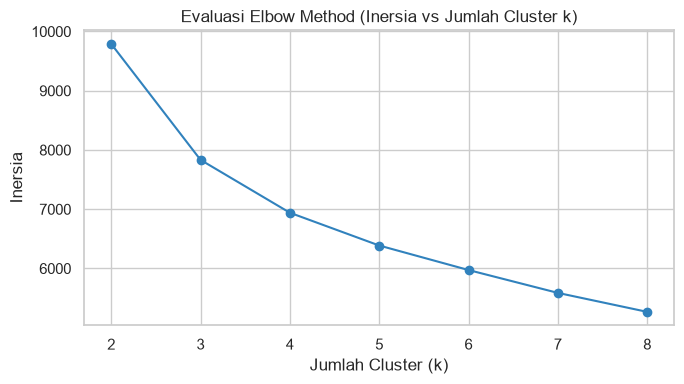

In [35]:
# Visualisasi 14.1: Evaluasi Metrik Elbow (Inersia) untuk Penentuan Cluster Optimal
k_range = range(2, 9)
inertias = []
silhouettes = []
davies_bouldins = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_train_pca)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_train_pca, km.labels_))
    davies_bouldins.append(davies_bouldin_score(X_train_pca, km.labels_))

plt.figure(figsize=(7, 4))
plt.plot(k_range, inertias, marker="o", color="#3182bd")
plt.title("Evaluasi Elbow Method (Inersia vs Jumlah Cluster k)")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inersia")
plt.tight_layout()
plt.show()

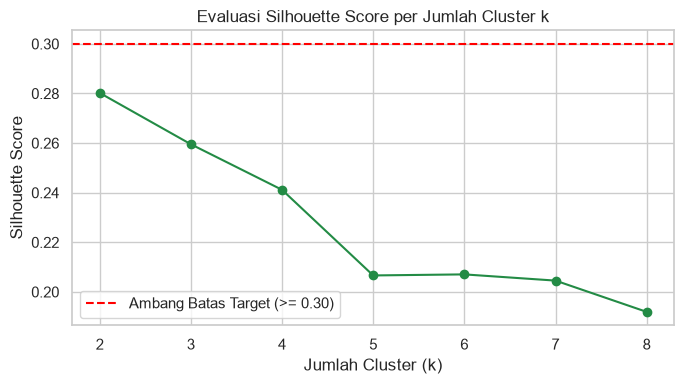

In [36]:
# Visualisasi 14.2: Evaluasi Silhouette Score (Ambang Batas Minimum >= 0.30)
plt.figure(figsize=(7, 4))
plt.plot(k_range, silhouettes, marker="o", color="#238b45")
plt.axhline(0.30, ls="--", color="red", label="Ambang Batas Target (>= 0.30)")
plt.title("Evaluasi Silhouette Score per Jumlah Cluster k")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette Score")
plt.legend()
plt.tight_layout()
plt.show()

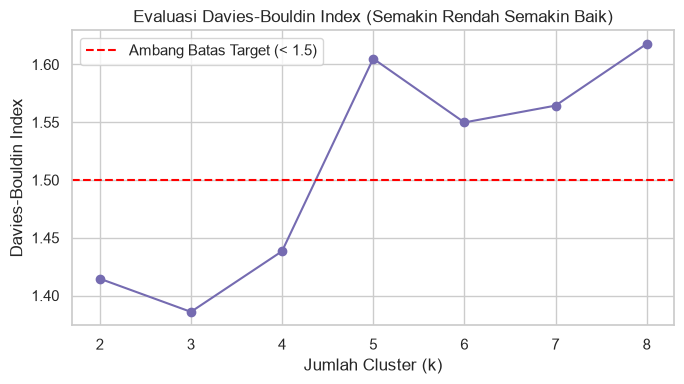

In [37]:
# Visualisasi 14.3: Evaluasi Davies-Bouldin Index (Target < 1.5)
plt.figure(figsize=(7, 4))
plt.plot(k_range, davies_bouldins, marker="o", color="#756bb1")
plt.axhline(1.5, ls="--", color="red", label="Ambang Batas Target (< 1.5)")
plt.title("Evaluasi Davies-Bouldin Index (Semakin Rendah Semakin Baik)")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Davies-Bouldin Index")
plt.legend()
plt.tight_layout()
plt.show()

---
# PENYIMPANAN ARTIFAK PIPELINE (DATASET FINAL)

Seluruh data yang telah dibersihkan, direkayasa, dan distandarisasi disimpan ke direktori `processed/` untuk langsung dimuat pada fase Modeling:

In [38]:
os.makedirs("processed", exist_ok=True)

# 1. Simpan dataset fitur scaled (untuk model clustering)
pd.DataFrame(X_train_scaled, columns=cols_log + cols_std).to_csv("processed/train_features_scaled.csv", index=False)
pd.DataFrame(X_test_scaled, columns=cols_log + cols_std).to_csv("processed/test_features_scaled.csv", index=False)

# 2. Simpan komponen PCA
pd.DataFrame(X_train_pca, columns=[f"PC_{i+1}" for i in range(X_train_pca.shape[1])]).to_csv("processed/train_pca.csv", index=False)
pd.DataFrame(X_test_pca, columns=[f"PC_{i+1}" for i in range(X_test_pca.shape[1])]).to_csv("processed/test_pca.csv", index=False)

# 3. Simpan dataset utuh (fitur asli + rekayasa + variabel profiling)
train_data.to_csv("processed/train_complete_profiling.csv", index=False)
test_data.to_csv("processed/test_complete_profiling.csv", index=False)

print("Seluruh artifak pemrosesan data berhasil disimpan ke folder 'processed/':")
for f in os.listdir("processed"):
    f_path = os.path.join("processed", f)
    print(f" - {f:30s} : {os.path.getsize(f_path):,} bytes")

Seluruh artifak pemrosesan data berhasil disimpan ke folder 'processed/':
 - cluster_test_scaled.csv        : 24,530 bytes
 - cluster_train_scaled.csv       : 98,044 bytes
 - profiling_test.csv             : 38,583 bytes
 - profiling_train.csv            : 153,482 bytes
 - test_complete_profiling.csv    : 46,043 bytes
 - test_features_scaled.csv       : 80,652 bytes
 - test_pca.csv                   : 40,545 bytes
 - train_complete_profiling.csv   : 183,516 bytes
 - train_features_scaled.csv      : 322,211 bytes
 - train_pca.csv                  : 162,097 bytes
